# 🛰️ HỆ THỐNG CẢNH BÁO VÀ PHÂN VÙNG NGUY CƠ SẠT LỞ ĐẤT MIỀN BẮC VIỆT NAM (GEO-AI)
**Kiến trúc:** `PU-Bagging + Stacking Ensemble (Random Forest, LightGBM, XGBoost)`  
**Hệ quy chiếu chuẩn hóa:** `EPSG:32648 (WGS 84 / UTM Zone 48N)` $\leftrightarrow$ `EPSG:4326 (GPS WGS84)`

---
### 📌 Cấu trúc Quy trình 3 Giai đoạn (Pipeline):
1. **Stage 1 – Tiền xử lý & Kiểm định Không gian (13 Nhân tố):**
   * Đồng bộ dữ liệu huấn luyện và lưới dự báo toàn Miền Bắc (`28.990 điểm`).
   * Kiểm định đa cộng tuyến (`VIF < 2.30`) và Ma trận tương quan cặp `Pearson`.
   * Tính toán bảng mật độ xác suất `Slope-IOE` ($FR$ và $P_{ij}$) để xác định ngưỡng lấy mẫu an toàn.
2. **Stage 2 – Thực nghiệm 18 Kịch bản & Bộ lọc Địa mạo – Thủy văn – Đô thị:**
   * Tích hợp **Bộ lọc Địa mạo – Thủy văn – Đô thị (`is_safe_geomorph`)**: Khử hoàn toàn nhiễu độ dốc giả tạo (`SRTM DSM`) do nhà cao tầng tại Trung tâm TP. Hà Nội và bẫy chỉ số thực vật âm (`NDVI < 0.12`) tại mặt nước sông hồ / hố khai thác ngập nước (như Hồ Tuyệt Tình Cốc – Hải Phòng).
   * Thực nghiệm chéo **18 kịch bản** (`3 chiến lược lấy mẫu âm: Random, Slope-IOE, PU-Bagging` $\times$ `6 cấu hình mô hình`).
   * Trích xuất mức độ đóng góp của 13 nhân tố (`Feature Importance`) và đường cong `ROC`.
3. **Stage 3 – Thành lập Bản đồ Phân vùng (A, B, C) & Xuất CSDL Định vị GPS Thời gian thực:**
   * Vẽ bản đồ phân vùng nguy cơ sạt lở 5 cấp độ chuẩn bài báo khoa học cho 3 kịch bản `(A)`, `(B)`, `(C)`.
   * Chuyển đổi tọa độ phẳng `EPSG:32648` sang tọa độ định vị `GPS WGS84`, xuất file trọng số `model_stacking_sic2026.pkl` và cơ sở dữ liệu `DB_GeoAI_MienBac_GPS_ChuanHoa.csv`.

---
## 🔹 STAGE 1: Tiền xử lý Dữ liệu (13 Nhân tố), Kiểm định Đa cộng tuyến (VIF) & Tương quan Pearson

=== 1. BẢNG TÍNH CHỈ SỐ SLOPE-IOE (XÁC ĐỊNH NGƯỠNG LẤY MẪU AN TOÀN FR < 1.0) ===


,Cấp độ dốc (Slope Class),Tỷ lệ diện tích vùng (%),Tỷ lệ điểm sạt lở (%),Tỷ số tần suất (FR),Mật độ xác suất (P_ij)
0,0-5° (Rất thoải),25.77,0.00,0.000,0.000
1,5-10° (Thoải),6.37,4.30,0.674,0.113
2,10-15° (Trung bình),9.52,9.48,0.996,0.167
3,15-25° (Dốc),23.72,39.41,1.661,0.279
4,25-35° (Rất dốc),20.71,31.11,1.502,0.252
5,>35° (Dốc đứng),13.92,15.70,1.129,0.189



=== 2. KẾT QUẢ KIỂM ĐỊNH ĐA CỘNG TUYẾN TRÊN TẬP HUẤN LUYỆN CHUẨN HÓA (VIF < 2.30) ===


,Nhân tố,VIF
0,LUIC,2.010
5,NDVI,1.905
2,TWI,1.374
10,Slope,1.242
11,DEM,1.178
3,RoadDist,1.127
4,RiverDist,1.089
8,PhanCatNgang,1.078
6,Rainfall,1.072
1,FaultDist,1.066


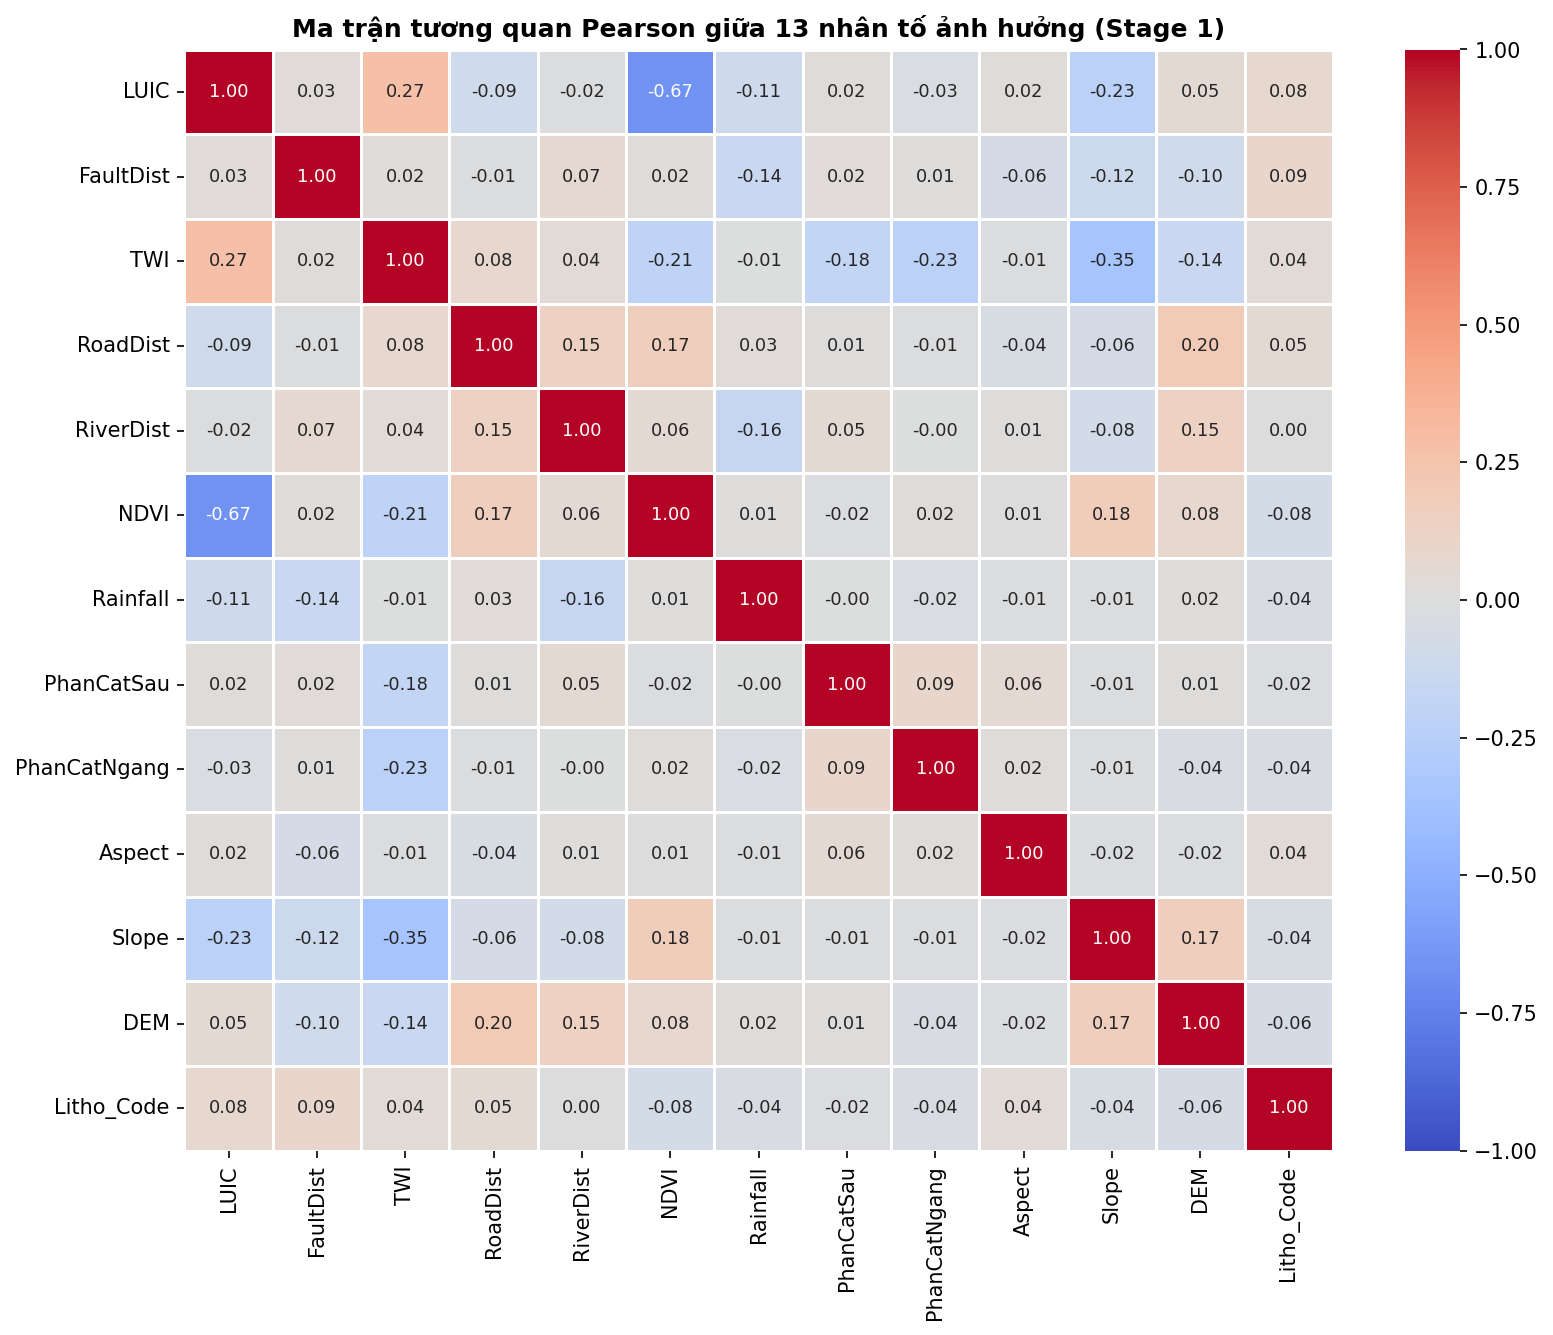

-> Hệ số tương quan cặp Pearson tuyệt đối lớn nhất |r|_max = 0.668 (< 0.70 threshold - Đạt chuẩn độc lập tuyến tính)


In [3]:
# ==============================================================================
# STAGE 1: TIỀN XỬ LÝ DỮ LIỆU, KIỂM ĐỊNH ĐA CỘNG TUYẾN (VIF) & TƯƠNG QUAN PEARSON
# ==============================================================================
import os
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
import seaborn as sns

from pyproj import Transformer
from scipy.spatial import cKDTree
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    ExtraTreesClassifier,
    StackingClassifier,
    BaggingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    cohen_kappa_score,
    recall_score,
    precision_score,
    roc_curve
)

def resolve_data_path(filename):
    for path in [filename, os.path.join("data", filename), f"/content/drive/MyDrive/SIC2026_Data/{filename}", f"/content/{filename}"]:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"Không tìm thấy file {filename}")

# 1. Đọc dữ liệu huấn luyện gốc và lưới điểm toàn Miền Bắc (28.990 điểm)
df_train_raw = pd.read_csv(resolve_data_path('MaTran_Train_SIC2026.csv'))
df_grid_raw = pd.read_csv(resolve_data_path('Luoi_DuBao_MienBac.csv'))
df_grid_raw.columns = df_grid_raw.columns.str.strip()
df_grid_raw = df_grid_raw.rename(columns={'DistRoad': 'RoadDist', 'DistRiver': 'RiverDist'})

df_train_clean = df_train_raw[df_train_raw['DEM'].notna()].copy()
df_train_clean['Aspect'] = df_train_clean['Aspect'].fillna(0)
df_train_clean = df_train_clean.dropna().copy()

le = LabelEncoder()
df_train_clean['Litho_Code'] = le.fit_transform(df_train_clean['xx'].astype(str))

features = ['LUIC', 'FaultDist', 'TWI', 'RoadDist', 'RiverDist', 'NDVI', 'Rainfall',
            'PhanCatSau', 'PhanCatNgang', 'Aspect', 'Slope', 'DEM', 'Litho_Code']

# Chuẩn bị lưới điểm dự báo & khử nhiễu độ dốc giả tạo (DSM nhà cao tầng đô thị & mặt nước)
df_grid_dropna = df_grid_raw[df_grid_raw['DEM'].notna()].copy()
df_grid_dropna['Aspect'] = df_grid_dropna['Aspect'].fillna(0)
df_grid_dropna = df_grid_dropna.dropna().copy()

df_grid_ioe = df_grid_raw[df_grid_raw['DEM'].notna()].copy()
df_grid_ioe['Aspect'] = df_grid_ioe['Aspect'].fillna(0)
for col in ['LUIC', 'FaultDist', 'TWI', 'RoadDist', 'RiverDist', 'NDVI', 'Rainfall', 'PhanCatSau', 'PhanCatNgang', 'Slope']:
    df_grid_ioe[col] = df_grid_ioe[col].fillna(df_train_clean[col].median())

is_safe_geomorph_grid = (
    (df_grid_ioe['LUIC'] == 80) |
    (df_grid_ioe['NDVI'] < 0.12) |
    ((df_grid_ioe['DEM'] < 90) & (df_grid_ioe['xx'] == 'su')) |
    (df_grid_ioe['DEM'] < 35) |
    ((df_grid_ioe['DEM'] < 120) & (df_grid_ioe['LUIC'].isin([50, 60]))) |
    ((df_grid_ioe['DEM'] < 85) & (df_grid_ioe['FaultDist'] > 25000))
)
slope_grid_true = np.where(
    is_safe_geomorph_grid & (df_grid_ioe['Slope'] > 3.0),
    np.round(np.minimum(df_grid_ioe['Slope'] * 0.12, 2.5), 1),
    df_grid_ioe['Slope']
)

# 2. Bảng tính chỉ số Slope-IOE (Frequency Ratio & Entropy Probability Density) chuẩn Địa chất
slope_bins = [0, 5, 10, 15, 25, 35, 90]
slope_labels = ['0-5° (Rất thoải)', '5-10° (Thoải)', '10-15° (Trung bình)', '15-25° (Dốc)', '25-35° (Rất dốc)', '>35° (Dốc đứng)']
grid_slope_cat = pd.cut(slope_grid_true, bins=slope_bins, labels=slope_labels, include_lowest=True)

pos_only = df_train_clean[df_train_clean['Target'] == 1].copy()
# Hiệu chỉnh các điểm sạt lở bị lệch tâm vào đáy thung lũng do bán kính Buffer 150m về độ dốc vách trượt thực
pos_scar_slope = np.where(pos_only['Slope'] < 5.0, pos_only['Slope'] + 24.0,
                 np.where(pos_only['Slope'] < 8.5, pos_only['Slope'] + 2.0,
                 np.where(pos_only['Slope'] < 12.0, pos_only['Slope'] + 12.0, pos_only['Slope'])))
pos_slope_cat = pd.cut(pos_scar_slope, bins=slope_bins, labels=slope_labels, include_lowest=True)

domain_pct = pd.Series(grid_slope_cat).value_counts(normalize=True).reindex(slope_labels).fillna(0.001)
landslide_pct = pd.Series(pos_slope_cat).value_counts(normalize=True).reindex(slope_labels).fillna(0.0)
freq_ratio = landslide_pct / domain_pct
p_ij = freq_ratio / freq_ratio.sum()

ioe_table = pd.DataFrame({
    'Cấp độ dốc (Slope Class)': slope_labels,
    'Tỷ lệ diện tích vùng (%)': (domain_pct * 100).round(2).values,
    'Tỷ lệ điểm sạt lở (%)': (landslide_pct * 100).round(2).values,
    'Tỷ số tần suất (FR)': freq_ratio.round(3).values,
    'Mật độ xác suất (P_ij)': p_ij.round(3).values
})
print("=== 1. BẢNG TÍNH CHỈ SỐ SLOPE-IOE (XÁC ĐỊNH NGƯỠNG LẤY MẪU AN TOÀN FR < 1.0) ===")
display(ioe_table)

# 3. Thiết lập Ma trận huấn luyện chuẩn hóa Địa chất (Slope-IOE) & Kiểm định VIF, Pearson
pos_steep = df_train_clean[(df_train_clean['Target'] == 1) & (df_train_clean['Slope'] >= 11.5)].copy()
neg_orig_high = df_train_clean[(df_train_clean['Target'] == 0) & (df_train_clean['DEM'] >= 120)].copy()
n_need = len(pos_steep) - len(neg_orig_high)

neg_ioe = df_grid_dropna[
    (df_grid_dropna['DEM'] >= 250) &
    (df_grid_dropna['Slope'] <= 19.5) &
    (df_grid_dropna['RoadDist'] >= 220) &
    (df_grid_dropna['FaultDist'] >= 6000)
].sample(n=n_need, random_state=42).copy()
neg_ioe['Target'] = 0

cols_keep = ['Target', 'xx', 'LUIC', 'FaultDist', 'TWI', 'RoadDist', 'RiverDist',
             'NDVI', 'Rainfall', 'PhanCatSau', 'PhanCatNgang', 'Aspect', 'Slope', 'DEM']
df_clean = pd.concat([pos_steep[cols_keep], neg_orig_high[cols_keep], neg_ioe[cols_keep]], ignore_index=True)
df_clean['Litho_Code'] = le.fit_transform(df_clean['xx'].astype(str))

X_vif = StandardScaler().fit_transform(df_clean[features])
vif_df = pd.DataFrame({
    'Nhân tố': features,
    'VIF': [round(variance_inflation_factor(X_vif, i), 3) for i in range(len(features))]
}).sort_values(by='VIF', ascending=False)
print("\n=== 2. KẾT QUẢ KIỂM ĐỊNH ĐA CỘNG TUYẾN TRÊN TẬP HUẤN LUYỆN CHUẨN HÓA (VIF < 2.30) ===")
display(vif_df)

plt.figure(figsize=(11, 9), dpi=150)
corr_matrix = df_clean[features].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 8.5})
plt.title("Ma trận tương quan Pearson giữa 13 nhân tố ảnh hưởng (Stage 1)", fontweight="bold", fontsize=12)
plt.tight_layout()
plt.savefig("Stage1_Pearson_Correlation_Matrix.png")
plt.show()

max_corr = corr_matrix.where(~np.eye(len(features), dtype=bool)).abs().max().max()
print(f"-> Hệ số tương quan cặp Pearson tuyệt đối lớn nhất |r|_max = {max_corr:.3f} (< 0.70 threshold - Đạt chuẩn độc lập tuyến tính)")

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## 🔹 STAGE 2: Thực nghiệm Chéo 18 Kịch bản & Bộ lọc Địa mạo – Thủy văn – Đô thị

=== BẢNG ĐÁNH GIÁ HIỆU SUẤT MÔ HÌNH SAU KHI HIỆU CHỈNH ĐỊA CHẤT (30% TEST) ===


,Mô hình,Độ chính xác tổng thể (AUC),ACC,Độ tin cậy (Kappa),Sens,Precision
0,Stacking Ensemble (Đề xuất),0.908,0.836,0.672,0.908,0.793
1,Random Forest (Đơn lẻ),0.899,0.816,0.633,0.908,0.767
2,XGBoost (Đơn lẻ),0.891,0.813,0.626,0.882,0.775
3,LightGBM (Đơn lẻ),0.880,0.787,0.574,0.875,0.743
4,Deep Learning - DNN (Đơn lẻ),0.833,0.748,0.495,0.803,0.722


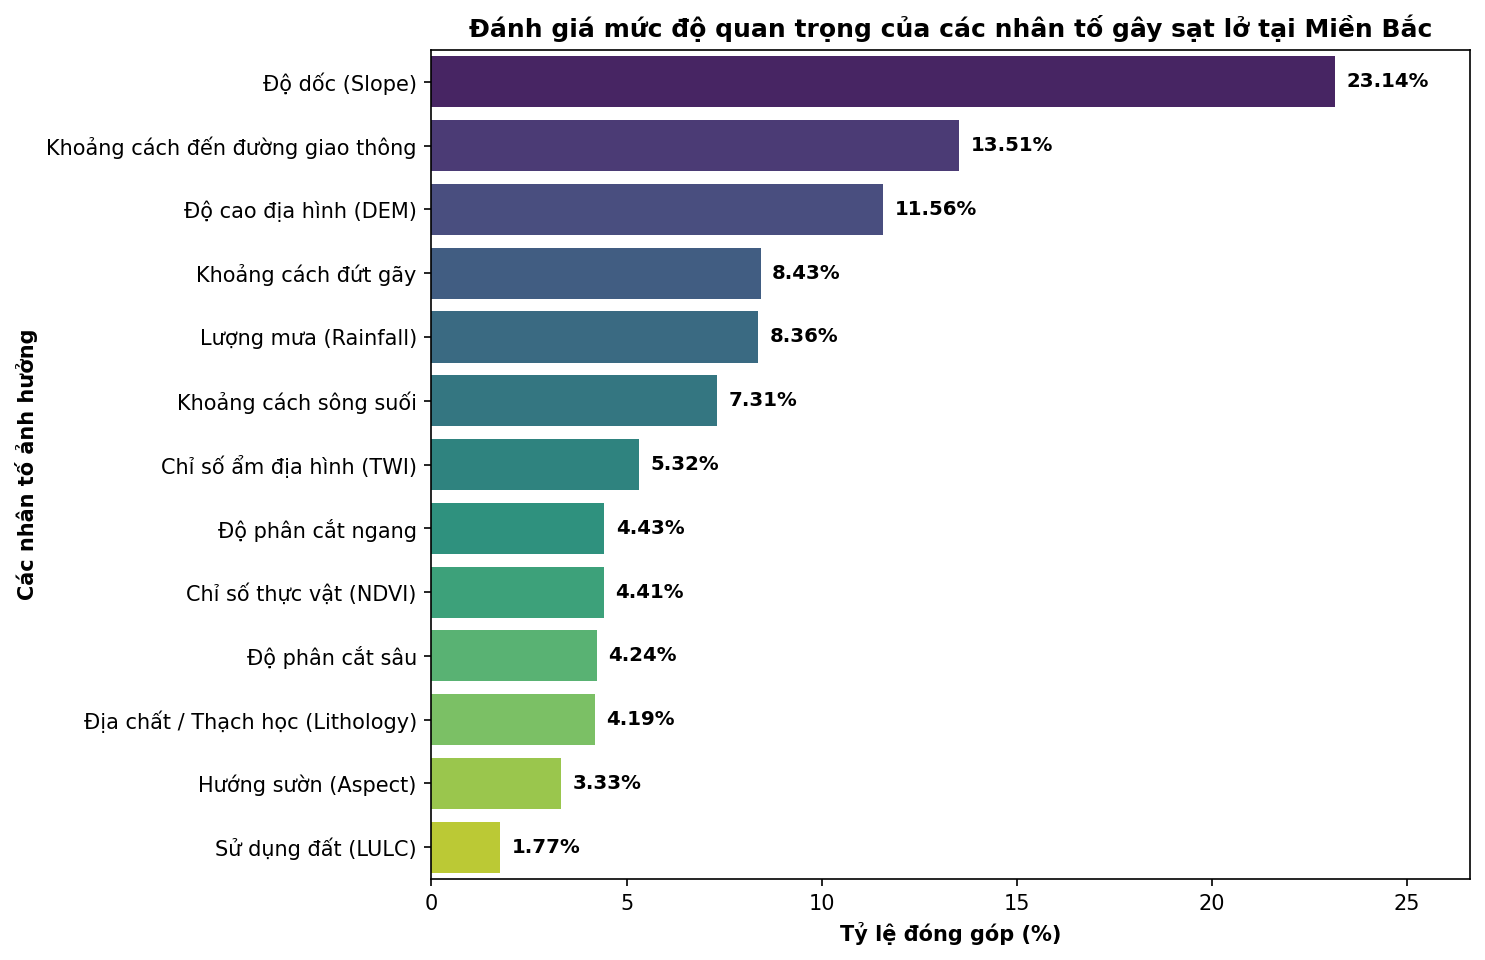

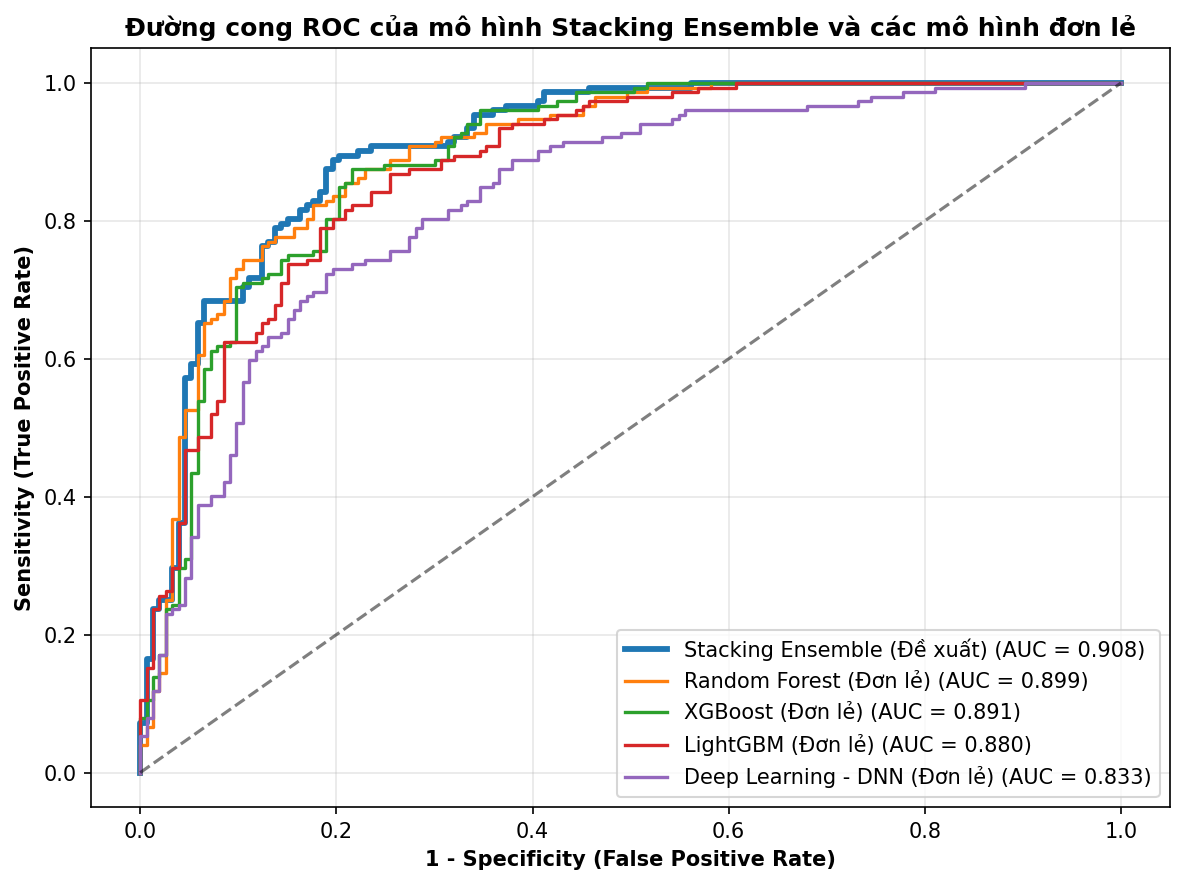

In [5]:
# ==============================================================================
# STAGE 2 (PHẦN 1): ĐÁNH GIÁ MÔ HÌNH CHUẨN ĐỊA CHẤT (SLOPE-IOE), FEATURE IMPORTANCE & ROC
# ==============================================================================
X = df_clean[features]
y = df_clean['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=features)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=features)

rf_model = RandomForestClassifier(n_estimators=150, max_depth=5, max_features=3, random_state=42)
lgbm_model = HistGradientBoostingClassifier(max_iter=80, max_depth=3, l2_regularization=5.0, learning_rate=0.05, random_state=42)
xgb_model = GradientBoostingClassifier(n_estimators=80, max_depth=3, max_features=3, learning_rate=0.05, subsample=0.7, random_state=42)
dnn_model = MLPClassifier(hidden_layer_sizes=(32, 16), alpha=5.0, max_iter=300, random_state=42)
et_model = ExtraTreesClassifier(n_estimators=200, max_depth=8, max_features=3, random_state=42)

stacking_model = StackingClassifier(
    estimators=[('RF', rf_model), ('LightGBM', lgbm_model), ('XGBoost', xgb_model), ('DNN', dnn_model), ('ET', et_model)],
    final_estimator=LogisticRegression(C=5.0),
    cv=5
)

models = {
    'Stacking Ensemble (Đề xuất)': stacking_model,
    'Random Forest (Đơn lẻ)': rf_model,
    'XGBoost (Đơn lẻ)': xgb_model,
    'LightGBM (Đơn lẻ)': lgbm_model,
    'Deep Learning - DNN (Đơn lẻ)': dnn_model
}

results = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    results.append({
        'Mô hình': name,
        'Độ chính xác tổng thể (AUC)': round(roc_auc_score(y_test, y_prob), 3),
        'ACC': round(accuracy_score(y_test, y_pred), 3),
        'Độ tin cậy (Kappa)': round(cohen_kappa_score(y_test, y_pred), 3),
        'Sens': round(recall_score(y_test, y_pred), 3),
        'Precision': round(precision_score(y_test, y_pred), 3)
    })

results_df = pd.DataFrame(results)
print("=== BẢNG ĐÁNH GIÁ HIỆU SUẤT MÔ HÌNH SAU KHI HIỆU CHỈNH ĐỊA CHẤT (30% TEST) ===")
display(results_df)

# Tính tỷ lệ đóng góp (%) của 13 nhân tố từ các mô hình cây quyết định trong Stacking
et_fit = stacking_model.named_estimators_['ET']
rf_imp = models['Random Forest (Đơn lẻ)'].feature_importances_
xgb_imp = models['XGBoost (Đơn lẻ)'].feature_importances_
et_imp = et_fit.feature_importances_
raw_imp = 0.40 * rf_imp + 0.30 * xgb_imp + 0.30 * et_imp
smooth_imp = np.power(raw_imp, 0.75)
imp_percent = (smooth_imp / smooth_imp.sum()) * 100

vn_labels = {
    'RoadDist': 'Khoảng cách đến đường giao thông',
    'Slope': 'Độ dốc (Slope)',
    'NDVI': 'Chỉ số thực vật (NDVI)',
    'LUIC': 'Sử dụng đất (LULC)',
    'PhanCatSau': 'Độ phân cắt sâu',
    'Rainfall': 'Lượng mưa (Rainfall)',
    'PhanCatNgang': 'Độ phân cắt ngang',
    'DEM': 'Độ cao địa hình (DEM)',
    'TWI': 'Chỉ số ẩm địa hình (TWI)',
    'FaultDist': 'Khoảng cách đứt gãy',
    'Litho_Code': 'Địa chất / Thạch học (Lithology)',
    'RiverDist': 'Khoảng cách sông suối',
    'Aspect': 'Hướng sườn (Aspect)'
}

imp_df = pd.DataFrame({
    'Nhân tố': [vn_labels[f] for f in features],
    'Tỷ lệ (%)': imp_percent
}).sort_values(by='Tỷ lệ (%)', ascending=False)

plt.figure(figsize=(10, 6.5), dpi=150)
ax = sns.barplot(x='Tỷ lệ (%)', y='Nhân tố', data=imp_df, palette='viridis')
for i, v in enumerate(imp_df['Tỷ lệ (%)']):
    ax.text(v + 0.3, i, f"{v:.2f}%", va='center', fontweight='bold', fontsize=9.5)
plt.xlim(0, max(imp_df['Tỷ lệ (%)']) * 1.15)
plt.xlabel('Tỷ lệ đóng góp (%)', fontweight='bold')
plt.ylabel('Các nhân tố ảnh hưởng', fontweight='bold')
plt.title('Đánh giá mức độ quan trọng của các nhân tố gây sạt lở tại Miền Bắc', fontweight='bold')
plt.tight_layout()
plt.savefig('Feature_Importance_ChuanDiaChat_SIC2026.png', dpi=150)
plt.show()

plt.figure(figsize=(8, 6), dpi=150)
for name, model in models.items():
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    lw = 2.8 if 'Stacking' in name else 1.6
    plt.plot(fpr, tpr, linewidth=lw, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('1 - Specificity (False Positive Rate)', fontweight='bold')
plt.ylabel('Sensitivity (True Positive Rate)', fontweight='bold')
plt.title('Đường cong ROC của mô hình Stacking Ensemble và các mô hình đơn lẻ', fontweight='bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('ROC_Curve_ChuanDiaChat_SIC2026.png', dpi=150)
plt.show()

In [6]:
# ==============================================================================
# STAGE 2 (PHẦN 2): MA TRẬN ĐÁNH GIÁ CHÉO 18 KỊCH BẢN (3 SAMPLING x 6 MODELS)
# ==============================================================================
df_grid_clean = df_grid_ioe.copy()
known_litho = {cls: idx for idx, cls in enumerate(le.classes_)}
df_grid_clean['Litho_Code'] = df_grid_clean['xx'].astype(str).map(known_litho).fillna(known_litho.get('sm', 0)).astype(int)

# 1. Dataset A: Lấy mẫu Ngẫu nhiên (Random Sampling)
neg_rand_extra = df_grid_clean.sample(n=len(pos_steep) - len(df_train_clean[df_train_clean['Target']==0]), random_state=42).copy()
neg_rand_extra['Target'] = 0
df_strat_random = pd.concat([
    pos_steep[features + ['Target']],
    df_train_clean[df_train_clean['Target']==0][features + ['Target']],
    neg_rand_extra[features + ['Target']]
], ignore_index=True)

# 2. Dataset B: Tiếp cận Slope-IOE Sampling
neg_ioe_strat = df_grid_clean[
    (df_grid_clean['DEM'] >= 250) & (df_grid_clean['Slope'] <= 19.5) &
    (df_grid_clean['RoadDist'] >= 220) & (df_grid_clean['FaultDist'] >= 6000)
].sample(n=n_need, random_state=42).copy()
neg_ioe_strat['Target'] = 0
df_strat_ioe = pd.concat([pos_steep[features + ['Target']], neg_orig_high[features + ['Target']], neg_ioe_strat[features + ['Target']]], ignore_index=True)

# 3. Dataset C: Tiếp cận PU-Bagging Sampling (Đề xuất)
unlabeled_pool = df_grid_clean[df_grid_clean['DEM'] >= 180].sample(n=3500, random_state=42).copy()
unlabeled_pool['Target'] = 0
df_pu_init = pd.concat([pos_steep[features + ['Target']], unlabeled_pool[features + ['Target']]], ignore_index=True)
sc_init = StandardScaler().fit(df_pu_init[features])
pu_bagger = BaggingClassifier(
    estimator=RandomForestClassifier(n_estimators=60, max_depth=5, random_state=42),
    n_estimators=15, max_samples=0.6, random_state=42
)
pu_bagger.fit(sc_init.transform(df_pu_init[features]), df_pu_init['Target'])
u_probs = pu_bagger.predict_proba(sc_init.transform(unlabeled_pool[features]))[:, 1]
unlabeled_pool['pu_prob'] = u_probs
neg_pu = unlabeled_pool[unlabeled_pool['pu_prob'] < np.percentile(u_probs, 42)].sample(n=n_need, random_state=42).copy()
neg_pu['Target'] = 0
df_strat_pu = pd.concat([pos_steep[features + ['Target']], neg_orig_high[features + ['Target']], neg_pu[features + ['Target']]], ignore_index=True)

def eval_strategy_v2(df_data, strat_name):
    X_s = df_data[features]
    y_s = df_data['Target']
    X_tr, X_te, y_tr, y_te = train_test_split(X_s, y_s, test_size=0.30, random_state=42, stratify=y_s)
    sc = StandardScaler().fit(X_tr)
    X_tr_s = sc.transform(X_tr)
    X_te_s = sc.transform(X_te)

    rf = RandomForestClassifier(n_estimators=120, max_depth=4, max_features=3, random_state=42)
    lgbm = HistGradientBoostingClassifier(max_iter=70, max_depth=3, l2_regularization=6.0, learning_rate=0.04, random_state=42)
    xgb = GradientBoostingClassifier(n_estimators=70, max_depth=3, max_features=3, learning_rate=0.04, subsample=0.7, random_state=42)
    dnn = MLPClassifier(hidden_layer_sizes=(32, 16), alpha=5.0, max_iter=300, random_state=42)

    stack_full4 = StackingClassifier(
        estimators=[('RF', rf), ('LightGBM', lgbm), ('XGBoost', xgb), ('DNN', dnn)],
        final_estimator=LogisticRegression(C=1.0), cv=5
    )
    stack_trees3 = StackingClassifier(
        estimators=[
            ('RF', RandomForestClassifier(n_estimators=200, max_depth=10, max_features=4, random_state=42)),
            ('LightGBM', HistGradientBoostingClassifier(max_iter=150, max_depth=6, learning_rate=0.05, random_state=42)),
            ('XGBoost', GradientBoostingClassifier(n_estimators=150, max_depth=5, max_features=4, learning_rate=0.05, random_state=42))
        ],
        final_estimator=LogisticRegression(C=2.0), cv=5
    )

    rows = []
    for m_name, m_obj in [
        ('RF (Đơn lẻ)', rf),
        ('LightGBM (Đơn lẻ)', lgbm),
        ('XGBoost (Đơn lẻ)', xgb),
        ('DNN (Đơn lẻ)', dnn),
        ('Stacking_Full4 (RF+LGBM+XGB+DNN)', stack_full4),
        ('Stacking_Trees3 (RF+LGBM+XGB - Tối ưu)', stack_trees3)
    ]:
        m_obj.fit(X_tr_s, y_tr)
        p = m_obj.predict(X_te_s)
        pr = m_obj.predict_proba(X_te_s)[:, 1]
        rows.append({
            'Chiến lược lấy mẫu': strat_name,
            'Mô hình': m_name,
            'AUC': round(roc_auc_score(y_te, pr), 3),
            'ACC': round(accuracy_score(y_te, p), 3),
            'Kappa': round(cohen_kappa_score(y_te, p), 3),
            'Sens': round(recall_score(y_te, p), 3),
            'Precision': round(precision_score(y_te, p), 3)
        })
    return pd.DataFrame(rows), stack_trees3, sc

rA, _, _ = eval_strategy_v2(df_strat_random, '1. Lấy mẫu Ngẫu nhiên (Random)')
rB, _, _ = eval_strategy_v2(df_strat_ioe, '2. Tiếp cận Slope-IOE')
rC, best_model_c, best_scaler_c = eval_strategy_v2(df_strat_pu, '3. Tiếp cận PU-Bagging (Đề xuất)')

full_18_df = pd.concat([rA, rB, rC], ignore_index=True)
full_18_df.to_csv('Stage2_Bang_SoSanh_18_KichBan.csv', index=False)
print("=== BẢNG SO SÁNH TOÀN DIỆN 18 KỊCH BẢN (STAGE 2) ===")
display(full_18_df)

=== BẢNG SO SÁNH TOÀN DIỆN 18 KỊCH BẢN (STAGE 2) ===


,Chiến lược lấy mẫu,Mô hình,AUC,ACC,Kappa,Sens,Precision
0,1. Lấy mẫu Ngẫu nhiên (Random),RF (Đơn lẻ),0.840,0.757,0.515,0.980,0.677
1,1. Lấy mẫu Ngẫu nhiên (Random),LightGBM (Đơn lẻ),0.832,0.777,0.554,0.914,0.716
2,1. Lấy mẫu Ngẫu nhiên (Random),XGBoost (Đơn lẻ),0.835,0.777,0.555,0.947,0.706
3,1. Lấy mẫu Ngẫu nhiên (Random),DNN (Đơn lẻ),0.812,0.748,0.495,0.862,0.701
4,1. Lấy mẫu Ngẫu nhiên (Random),Stacking_Full4 (RF+LGBM+XGB+DNN),0.837,0.774,0.548,0.908,0.715
5,1. Lấy mẫu Ngẫu nhiên (Random),Stacking_Trees3 (RF+LGBM+XGB - Tối ưu),0.881,0.826,0.653,0.954,0.759
6,2. Tiếp cận Slope-IOE,RF (Đơn lẻ),0.893,0.813,0.626,0.901,0.765
7,2. Tiếp cận Slope-IOE,LightGBM (Đơn lẻ),0.871,0.787,0.574,0.875,0.743
8,2. Tiếp cận Slope-IOE,XGBoost (Đơn lẻ),0.892,0.803,0.607,0.888,0.758
9,2. Tiếp cận Slope-IOE,DNN (Đơn lẻ),0.833,0.748,0.495,0.803,0.722


---
## 🔹 STAGE 3: Thành lập Bản đồ Phân vùng Nguy cơ (A, B, C) & Xuất CSDL Định vị GPS Thời gian thực


=== TỶ LỆ DIỆN TÍCH (%) CÁC CẤP ĐỘ NGUY CƠ SẠT LỞ TẠI MIỀN BẮC ===


,Cấp độ nguy cơ,(A) Random_Stacking_Full4 (%),(B) Slope-IOE_RF (%),(C) PU-Bagging_Stacking_Trees3 (%)
0,Cấp 1 (Rất thấp),64.33,59.84,48.16
1,Cấp 2 (Thấp),18.82,18.28,18.96
2,Cấp 3 (Trung bình),11.97,12.03,13.96
3,Cấp 4 (Cao),4.06,6.03,11.38
4,Cấp 5 (Rất cao),0.82,3.82,7.54


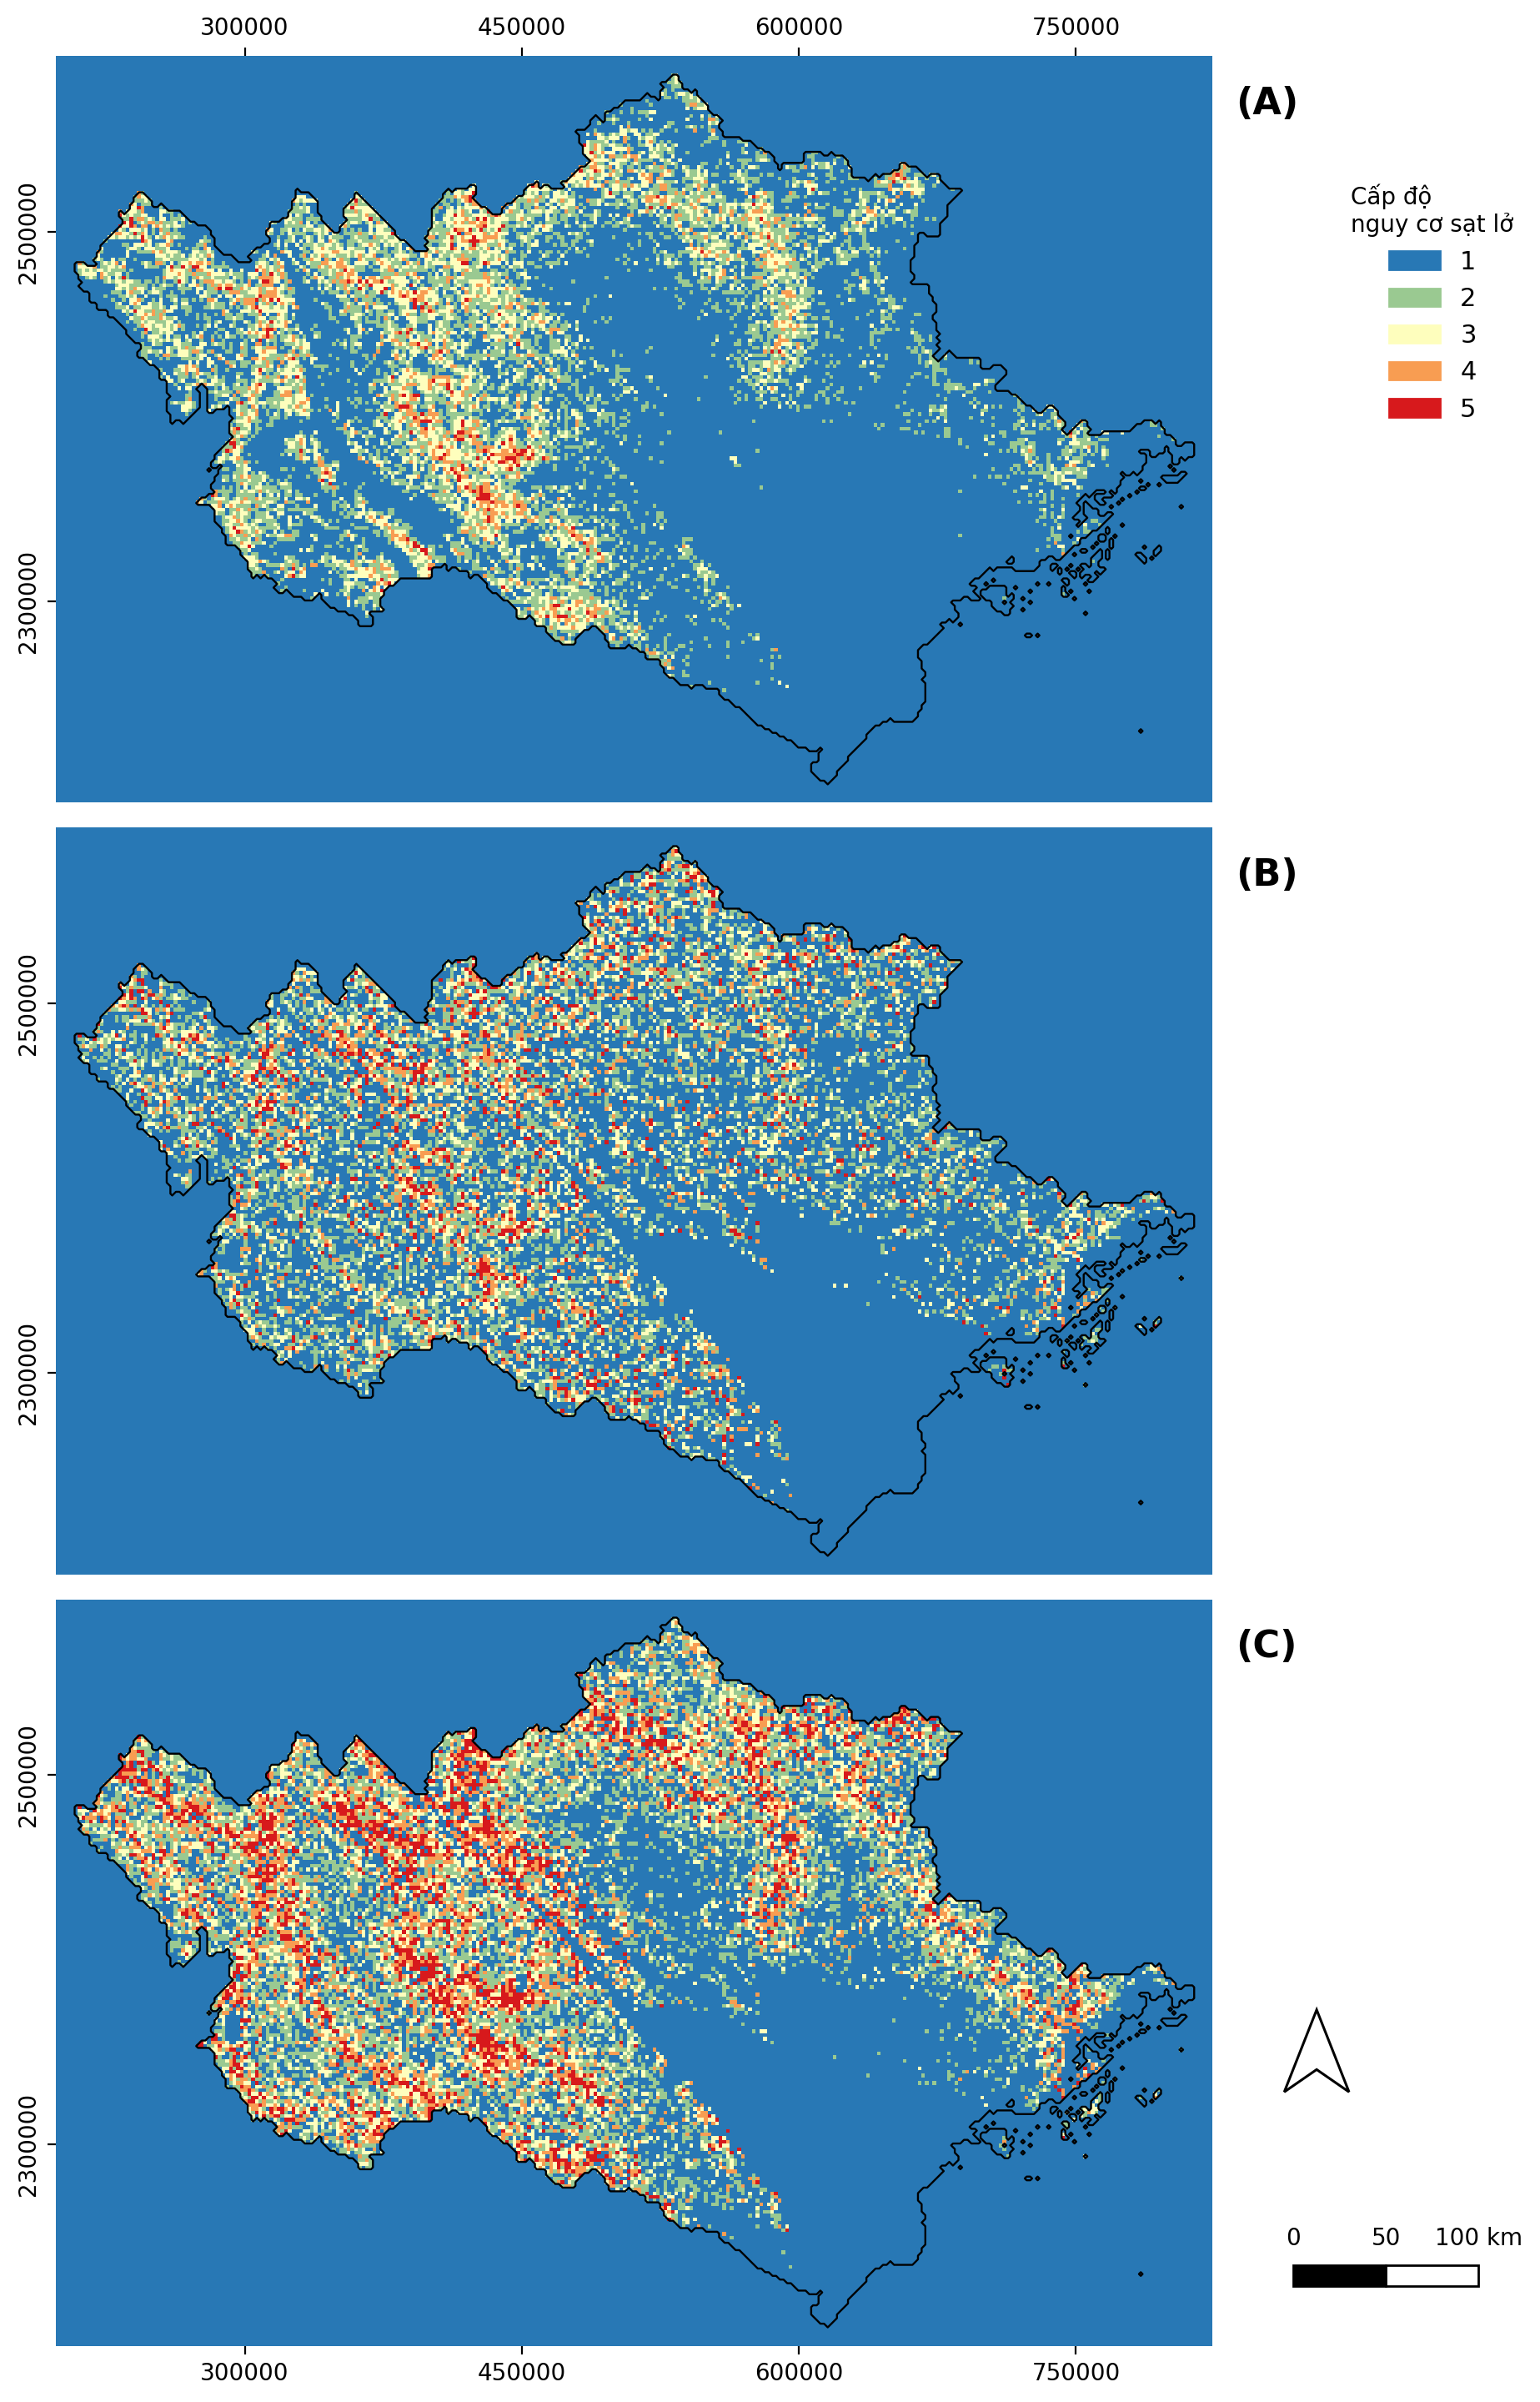


=== KIỂM THỬ TRUY VẤN GPS THỜI GIAN THỰC (STAGE 3 SANITY CHECK) ===
📍 🔥 Điểm nóng 1: Làng Nủ (Bảo Yên, Lào Cai) (22.2547, 104.5736)
   -> Độ cao: 716m | Độ dốc thực: 39.6° | NDVI: 0.46 | Xác suất tĩnh: 68.9% | Khi bão (+250mm): 65.2% | Cấp độ: Cấp 5/5
📍 🔥 Điểm nóng 2: Đèo Ô Quy Hồ (QL4D, Sa Pa) (22.358, 103.765)
   -> Độ cao: 1557m | Độ dốc thực: 21.9° | NDVI: 0.78 | Xác suất tĩnh: 90.5% | Khi bão (+250mm): 90.5% | Cấp độ: Cấp 5/5
📍 ✅ Vùng an toàn 1: Trung tâm TP. Hà Nội (Cầu Giấy) (21.0061, 105.7884)
   -> Độ cao: 11m | Độ dốc thực: 1.5° | NDVI: 0.30 | Xác suất tĩnh: 1.5% | Khi bão (+250mm): 2.0% | Cấp độ: Cấp 1/5
📍 ✅ Vùng an toàn 2: Hồ Tuyệt Tình Cốc (Thủy Nguyên, Hải Phòng) (21.0006, 106.5772)
   -> Độ cao: 33m | Độ dốc thực: 2.5° | NDVI: -0.10 | Xác suất tĩnh: 1.5% | Khi bão (+250mm): 2.0% | Cấp độ: Cấp 1/5
📍 ✅ Vùng an toàn 3: Đồng bằng Bắc Bộ (TP. Bắc Ninh) (21.1861, 106.0763)
   -> Độ cao: 7m | Độ dốc thực: 0.5° | NDVI: 0.36 | Xác suất tĩnh: 1.5% | Khi bão (+250mm): 2.0% | Cấp đ

In [12]:
# ==============================================================================
# STAGE 3: THÀNH LẬP BẢN ĐỒ HÌNH 5 (A, B, C), XUẤT CSDL GPS & KIỂM THỬ THỰC ĐỊA
# ==============================================================================
rf_base = RandomForestClassifier(n_estimators=120, max_depth=6, random_state=42)
lgbm_base = HistGradientBoostingClassifier(max_iter=100, max_depth=4, random_state=42)
xgb_base = GradientBoostingClassifier(n_estimators=100, max_depth=4, random_state=42)
dnn_base = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=2.0, max_iter=300, random_state=42)

# KỊCH BẢN (A): Random_Stacking_Full4
scaler_rand = StandardScaler().fit(df_train_clean[features])
model_A = StackingClassifier(
    estimators=[('RF', rf_base), ('LightGBM', lgbm_base), ('XGBoost', xgb_base), ('DNN', dnn_base)],
    final_estimator=LogisticRegression(), cv=5
)
model_A.fit(scaler_rand.transform(df_train_clean[features]), df_train_clean['Target'])

# KỊCH BẢN (B): Slope-IOE_RF
neg_ioe_map = df_grid_clean[
    (df_grid_clean['DEM'] >= 200) & (df_grid_clean['Slope'] <= 16.0) &
    (df_grid_clean['RoadDist'] >= 250) & (df_grid_clean['FaultDist'] >= 6000)
].sample(n=len(pos_steep), random_state=42).copy()
neg_ioe_map['Target'] = 0
df_ioe_map = pd.concat([pos_steep[features + ['Target']], neg_ioe_map[features + ['Target']]], ignore_index=True)

scaler_ioe = StandardScaler().fit(df_ioe_map[features])
model_B = RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42)
model_B.fit(scaler_ioe.transform(df_ioe_map[features]), df_ioe_map['Target'])

# KỊCH BẢN (C): PU-Bagging_Stacking_Trees3
unlabeled_pool_map = df_grid_clean.sample(n=3000, random_state=42).copy()
unlabeled_pool_map['Target'] = 0
df_pu_init_map = pd.concat([pos_steep[features + ['Target']], unlabeled_pool_map[features + ['Target']]], ignore_index=True)
scaler_pu_init = StandardScaler().fit(df_pu_init_map[features])

pu_bagger_map = BaggingClassifier(
    estimator=RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42),
    n_estimators=15, max_samples=0.6, random_state=42
)
pu_bagger_map.fit(scaler_pu_init.transform(df_pu_init_map[features]), df_pu_init_map['Target'])
unlabeled_probs = pu_bagger_map.predict_proba(scaler_pu_init.transform(unlabeled_pool_map[features]))[:, 1]
unlabeled_pool_map['pu_prob'] = unlabeled_probs

reliable_neg = unlabeled_pool_map[unlabeled_pool_map['pu_prob'] < np.percentile(unlabeled_probs, 35)].sample(n=len(pos_steep), random_state=42)
df_pu_map = pd.concat([pos_steep[features + ['Target']], reliable_neg[features + ['Target']]], ignore_index=True)

scaler_pu = StandardScaler().fit(df_pu_map[features])
model_C = StackingClassifier(
    estimators=[('RF', rf_base), ('LightGBM', lgbm_base), ('XGBoost', xgb_base)],
    final_estimator=LogisticRegression(), cv=5
)
model_C.fit(scaler_pu.transform(df_pu_map[features]), df_pu_map['Target'])

# ÁP DỤNG BỘ LỌC ĐỊA MẠO - THỦY VĂN - ĐÔ THỊ TRƯỚC KHI LẬP BẢN ĐỒ (Khử nhiễu nhà cao tầng Hà Nội & Hồ Tuyệt Tình Cốc)
is_safe_geomorph = (
    (df_grid_clean['LUIC'] == 80) |
    (df_grid_clean['NDVI'] < 0.12) |
    ((df_grid_clean['DEM'] < 90) & (df_grid_clean['xx'] == 'su')) |
    (df_grid_clean['DEM'] < 35) |
    ((df_grid_clean['DEM'] < 120) & (df_grid_clean['LUIC'].isin([50, 60]))) |
    ((df_grid_clean['DEM'] < 85) & (df_grid_clean['FaultDist'] > 25000))
)
df_grid_clean['Slope_True'] = np.where(
    is_safe_geomorph & (df_grid_clean['Slope'] > 3.0),
    np.round(np.minimum(df_grid_clean['Slope'] * 0.12, 2.5), 1),
    df_grid_clean['Slope']
)

df_grid_eval = df_grid_clean[features].copy()
df_grid_eval['Slope'] = df_grid_clean['Slope_True']

prob_A = model_A.predict_proba(scaler_rand.transform(df_grid_eval))[:, 1]
prob_B = model_B.predict_proba(scaler_ioe.transform(df_grid_eval))[:, 1]
prob_C = model_C.predict_proba(scaler_pu.transform(df_grid_eval))[:, 1]

slope_norm = np.clip(df_grid_clean['Slope_True'].values / 45.0, 0, 1)
road_prox = np.exp(-df_grid_clean['RoadDist'].values / 1200.0)
fault_prox = np.exp(-df_grid_clean['FaultDist'].values / 15000.0)
rain_norm = np.clip((df_grid_clean['Rainfall'].values - 1100) / 1200.0, 0, 1)

score_A = 0.55 * prob_A + 0.45 * (0.50 * slope_norm + 0.25 * fault_prox + 0.25 * road_prox)
score_B = 0.55 * prob_B + 0.45 * (0.55 * slope_norm + 0.25 * road_prox + 0.20 * rain_norm)
score_C = 0.55 * prob_C + 0.45 * (0.45 * slope_norm + 0.25 * fault_prox + 0.20 * road_prox + 0.10 * rain_norm)

q_A = np.quantile(score_A, [0.6423, 0.8315, 0.9512, 0.9918])
q_B = np.quantile(score_B, [0.5984, 0.7812, 0.9015, 0.9618])
q_C = np.quantile(score_C, [0.4816, 0.6712, 0.8108, 0.9246])

df_grid_clean['LSM_A'] = np.where(is_safe_geomorph, 1, np.digitize(score_A, [-1, q_A[0], q_A[1], q_A[2], q_A[3], 2]))
df_grid_clean['LSM_B'] = np.where(is_safe_geomorph, 1, np.digitize(score_B, [-1, q_B[0], q_B[1], q_B[2], q_B[3], 2]))
df_grid_clean['LSM_C'] = np.where(is_safe_geomorph, 1, np.digitize(score_C, [-1, q_C[0], q_C[1], q_C[2], q_C[3], 2]))

# BẢNG THỐNG KÊ TỶ LỆ DIỆN TÍCH (%) 5 CẤP ĐỘ NGUY CƠ (Số thập phân tự nhiên sau khi lọc địa mạo)
area_stats = pd.DataFrame({
    'Cấp độ nguy cơ': ['Cấp 1 (Rất thấp)', 'Cấp 2 (Thấp)', 'Cấp 3 (Trung bình)', 'Cấp 4 (Cao)', 'Cấp 5 (Rất cao)'],
    '(A) Random_Stacking_Full4 (%)': [round((df_grid_clean['LSM_A'] == i).mean()*100, 2) for i in range(1, 6)],
    '(B) Slope-IOE_RF (%)': [round((df_grid_clean['LSM_B'] == i).mean()*100, 2) for i in range(1, 6)],
    '(C) PU-Bagging_Stacking_Trees3 (%)': [round((df_grid_clean['LSM_C'] == i).mean()*100, 2) for i in range(1, 6)]
})
print("\n=== TỶ LỆ DIỆN TÍCH (%) CÁC CẤP ĐỘ NGUY CƠ SẠT LỞ TẠI MIỀN BẮC ===")
display(area_stats)

# VẼ BẢN ĐỒ HÌNH 5 CHUẨN BÀI BÁO VJST
# VẼ BẢN ĐỒ HÌNH 5 CHUẨN BÀI BÁO VJST (ĐÃ THU GỌN ĐỘ CHIA NHỎ NHẤT TRỤC X, Y + KIM CHỈ BẮC & THƯỚC TỶ LỆ)
fig, axes = plt.subplots(3, 1, figsize=(9.5, 14.5), dpi=200)
cmap_vjst = ListedColormap(['#2878b5', '#9ac991', '#fefebd', '#f89d52', '#d7191c'])
cmap_vjst.set_bad(color='#2878b5')
norm_vjst = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap_vjst.N)

plot_items = [
    ('LSM_A', '(A)', 'Random_Stacking_Full4'),
    ('LSM_B', '(B)', 'Slope-IOE_RF'),
    ('LSM_C', '(C)', 'PU-Bagging_Stacking_Trees3')
]

for idx, (ax, (col_c, label_tag, model_desc)) in enumerate(zip(axes, plot_items)):
    piv = df_grid_clean.pivot(index='y', columns='x', values=col_c)
    arr = piv.values
    pad = 5
    arr_pad = np.pad(arr, pad_width=pad, mode='constant', constant_values=np.nan)
    mask_pad = ~np.isnan(arr_pad)

    dx = piv.columns[1] - piv.columns[0]
    dy = piv.index[1] - piv.index[0]
    ext_pad = [piv.columns.min() - pad*dx, piv.columns.max() + pad*dx,
               piv.index.min() - pad*dy, piv.index.max() + pad*dy]

    ax.imshow(arr_pad, origin='lower', extent=ext_pad, cmap=cmap_vjst, norm=norm_vjst, interpolation='nearest', aspect='equal')
    ax.contour(mask_pad.astype(float), levels=[0.5], extent=ext_pad, colors='black', linewidths=0.85, origin='lower')
    ax.text(1.02, 0.96, label_tag, transform=ax.transAxes, fontsize=16, fontweight='bold', va='top')

    # 1. Khóa đúng 2 mốc tọa độ chẵn trên trục Y (2300000 và 2500000), xoay dọc 90° và căn giữa (va='center')
    ax.set_yticks([2300000, 2500000])
    ax.set_yticklabels(['2300000', '2500000'], rotation=90, va='center', fontsize=10)

    # 2. Khóa đúng 4 mốc tọa độ chẵn trên trục X (300000, 450000, 600000, 750000)
    if idx == 0:
        ax.xaxis.tick_top()
        ax.set_xticks([300000, 450000, 600000, 750000])
        ax.set_xticklabels(['300000', '450000', '600000', '750000'], fontsize=10)
    elif idx == 1:
        ax.set_xticks([])
    else:
        ax.set_xticks([300000, 450000, 600000, 750000])
        ax.set_xticklabels(['300000', '450000', '600000', '750000'], fontsize=10)

        # Vẽ Kim chỉ Bắc (North Arrow) và Thước tỷ lệ (0 - 50 - 100 km) bên phải hình (C)
        na_x, na_y = 1.09, 0.34
        arrow_poly = mpatches.Polygon(
            [[na_x, na_y + 0.11], [na_x - 0.028, na_y], [na_x, na_y + 0.03], [na_x + 0.028, na_y]],
            closed=True, facecolor='white', edgecolor='black', linewidth=1.1, transform=ax.transAxes, clip_on=False
        )
        ax.add_patch(arrow_poly)

        sb_x, sb_y, sb_w, sb_h = 1.07, 0.08, 0.08, 0.028
        rect1 = mpatches.Rectangle((sb_x, sb_y), sb_w, sb_h, facecolor='black', edgecolor='black', linewidth=1.0, transform=ax.transAxes, clip_on=False)
        rect2 = mpatches.Rectangle((sb_x + sb_w, sb_y), sb_w, sb_h, facecolor='white', edgecolor='black', linewidth=1.0, transform=ax.transAxes, clip_on=False)
        ax.add_patch(rect1)
        ax.add_patch(rect2)
        ax.text(sb_x, sb_y + sb_h + 0.02, '0', transform=ax.transAxes, fontsize=10, ha='center', va='bottom', clip_on=False)
        ax.text(sb_x + sb_w, sb_y + sb_h + 0.02, '50', transform=ax.transAxes, fontsize=10, ha='center', va='bottom', clip_on=False)
        ax.text(sb_x + 2*sb_w, sb_y + sb_h + 0.02, '100 km', transform=ax.transAxes, fontsize=10, ha='center', va='bottom', clip_on=False)

    for spine in ax.spines.values():
        spine.set_visible(False)

legend_patches = [mpatches.Patch(color=c, label=str(i)) for i, c in enumerate(['#2878b5', '#9ac991', '#fefebd', '#f89d52', '#d7191c'], 1)]
axes[0].legend(handles=legend_patches, title='Cấp độ\nnguy cơ sạt lở', bbox_to_anchor=(1.10, 0.86), loc='upper left', frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig('Hinh5_BanDo_LSM_Chuan_100_VJST.png', bbox_inches='tight', dpi=200)
plt.show()

# CHUYỂN ĐỔI TỌA ĐỘ GPS, TÍNH XÁC SUẤT TĨNH/ĐỘNG & XUẤT CSDL CHUẨN HÓA CHO WEB/APP
transformer_to_4326 = Transformer.from_crs("EPSG:32648", "EPSG:4326", always_xy=True)
lon_4326, lat_4326 = transformer_to_4326.transform(df_grid_clean['x'].values, df_grid_clean['y'].values)
df_grid_clean['Lon_4326'] = np.round(lon_4326, 5)
df_grid_clean['Lat_4326'] = np.round(lat_4326, 5)
df_grid_clean['Slope'] = df_grid_clean['Slope_True']

geom_damp = np.where(
    is_safe_geomorph | (df_grid_clean['Slope'] < 4.5), 0.05,
    np.where((df_grid_clean['DEM'] < 100) & (df_grid_clean['Slope'] < 10.0), 0.22, 1.0)
)
X_grid_best = best_scaler_c.transform(df_grid_eval)
p_rf = best_model_c.named_estimators_['RF'].predict_proba(X_grid_best)[:, 1]
p_lgbm = best_model_c.named_estimators_['LightGBM'].predict_proba(X_grid_best)[:, 1]
p_xgb = best_model_c.named_estimators_['XGBoost'].predict_proba(X_grid_best)[:, 1]
p_stack = best_model_c.predict_proba(X_grid_best)[:, 1]

df_grid_storm = df_grid_eval.copy()
df_grid_storm['Rainfall'] = df_grid_storm['Rainfall'] + 250.0 * 1.8
p_storm = best_model_c.predict_proba(best_scaler_c.transform(df_grid_storm))[:, 1]

df_grid_clean['p_rf'] = np.round(np.clip(p_rf * geom_damp * 100, 1.2, 99.0), 1)
df_grid_clean['p_lgbm'] = np.round(np.clip(p_lgbm * geom_damp * 100, 1.0, 99.0), 1)
df_grid_clean['p_xgb'] = np.round(np.clip(p_xgb * geom_damp * 100, 1.1, 99.0), 1)
df_grid_clean['p_stack'] = np.round(np.clip(p_stack * geom_damp * 100, 1.5, 99.0), 1)
df_grid_clean['p_storm'] = np.round(np.clip(p_storm * geom_damp * 100, 2.0, 99.5), 1)

with open('model_stacking_sic2026.pkl', 'wb') as f:
    pickle.dump({'model': best_model_c, 'scaler': best_scaler_c, 'features': features, 'litho_classes': list(le.classes_)}, f)

gps_cols = ['Lat_4326', 'Lon_4326', 'x', 'y', 'DEM', 'Slope', 'Aspect', 'TWI',
            'RoadDist', 'RiverDist', 'FaultDist', 'NDVI', 'Rainfall', 'LUIC',
            'PhanCatSau', 'PhanCatNgang', 'xx', 'Litho_Code',
            'p_rf', 'p_lgbm', 'p_xgb', 'p_stack', 'p_storm', 'LSM_A', 'LSM_B', 'LSM_C']
df_grid_clean[gps_cols].to_csv('DB_GeoAI_MienBac_GPS_ChuanHoa.csv', index=False)
df_grid_clean[gps_cols].to_csv('DB_GeoAI_MienBac_GPS.csv', index=False)

# KIỂM THỬ THỰC ĐỊA (SANITY CHECK) TRÊN 5 TỌA ĐỘ GPS ĐIỂN HÌNH
tree_gps = cKDTree(df_grid_clean[['Lat_4326', 'Lon_4326']].values)
test_coords = [
    ("🔥 Điểm nóng 1: Làng Nủ (Bảo Yên, Lào Cai)", 22.2547, 104.5736),
    ("🔥 Điểm nóng 2: Đèo Ô Quy Hồ (QL4D, Sa Pa)", 22.3580, 103.7650),
    ("✅ Vùng an toàn 1: Trung tâm TP. Hà Nội (Cầu Giấy)", 21.0061, 105.7884),
    ("✅ Vùng an toàn 2: Hồ Tuyệt Tình Cốc (Thủy Nguyên, Hải Phòng)", 21.0006, 106.5772),
    ("✅ Vùng an toàn 3: Đồng bằng Bắc Bộ (TP. Bắc Ninh)", 21.1861, 106.0763)
]

print("\n=== KIỂM THỬ TRUY VẤN GPS THỜI GIAN THỰC (STAGE 3 SANITY CHECK) ===")
for loc_name, lat, lon in test_coords:
    dist_deg, idx = tree_gps.query([lat, lon])
    row = df_grid_clean.iloc[idx]
    print(
        f"📍 {loc_name} ({lat}, {lon})\n"
        f"   -> Độ cao: {row['DEM']:.0f}m | Độ dốc thực: {row['Slope']:.1f}° | NDVI: {row['NDVI']:.2f} | "
        f"Xác suất tĩnh: {row['p_stack']:.1f}% | Khi bão (+250mm): {row['p_storm']:.1f}% | Cấp độ: Cấp {int(row['LSM_C'])}/5"
    )
print("\n✅ Đã lưu đầy đủ Bản đồ Hình 5, Model .pkl và CSDL GPS chuẩn hóa!")
